# Anatomy of Persuasion · Delta timing

**Where do the later deltas go when the observation window gets longer?** We examine the first verified OP delta in each archived branch, then vary the prediction window and rebuild the risk set.

The first plots describe timing **among branches with a verified award**. Their cumulative curves are percentages of observed awards. Population-level rates come from the separate window explorer, which includes eligible branches without awards.

Run with pandas, NumPy, Matplotlib, and ipywidgets in the notebook kernel. The notebook rebuilds the timing inputs if they are missing.

In [6]:
from functools import lru_cache
from io import BytesIO
import json
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
import numpy as np
import pandas as pd
from IPython.display import display


REPO = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "team-setup").is_dir() and (path / "pyproject.toml").is_file()
)
BASE = REPO / "project/notebooks/nested-replies-analysis"
FIGURES = BASE / "delta_timing_analysis"
DATA = REPO / "project/data/processed/delta-timing-analysis"
BUILDER = BASE / "op_engagement_study/build_branch_dataset.py"
SPLITS = {"train": "Training", "heldout": "Held-out"}
COLORS = {"train": "#20768b", "heldout": "#9d572d"}
DEFAULT_OBSERVATION_HOURS = 24
DEFAULT_FOLLOWUP_HOURS = 168
frames, limits = {}, {}
for split in SPLITS:
    folder = DATA / split
    if not all((folder / name).is_file() for name in ("branches.parquet", "audit.json")):
        subprocess.run(
            [sys.executable, str(BUILDER), "--split", split, "--timing-features"], check=True
        )
    frames[split] = pd.read_parquet(folder / "branches.parquet")
    limits[split] = json.loads((folder / "audit.json").read_text())["followup_boundary_utc"]

## Time from branch opening to its first observed award

The histogram uses disjoint bins ending at the marked time. The table and ECDF show cumulative shares. Solid curves use the OP award comment's creation time. Dotted curves use the earliest DeltaBot confirmation for that branch. Seeing the two clocks together helps explain why some windows have uncertain outcomes. The plots include archived awards even on branches that fail the original 24-hour eligibility check.

Training: 6,540 dated first awards; 0 verified branches with missing or invalid opening-to-award time.
Held-out: 1,537 dated first awards; 0 verified branches with missing or invalid opening-to-award time.


count  share of observed first awards (%)
split    by                                              
Training 1 h     2488                               38.04
         6 h     4606                               70.43
         24 h    6067                               92.77
         3 d     6426                               98.26
         7 d     6496                               99.33
         14 d    6516                               99.63
         >14 d     24                                0.37
Held-out 1 h      727                               47.30
         6 h     1261                               82.04
         24 h    1487                               96.75
         3 d     1526                               99.28
         7 d     1534                               99.80
         14 d    1536                               99.93
         >14 d      1                                0.07

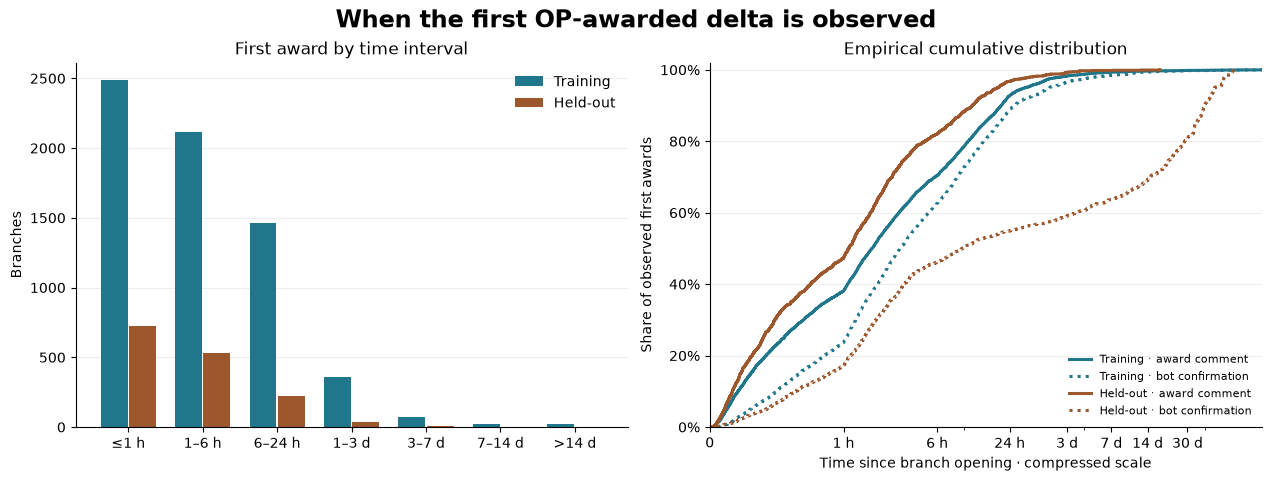

In [7]:
thresholds = np.array([1, 6, 24, 72, 168, 336])
milestones = ["1 h", "6 h", "24 h", "3 d", "7 d", "14 d"]
bin_names = ["≤1 h", "1–6 h", "6–24 h", "1–3 d", "3–7 d", "7–14 d", ">14 d"]
timing_rows = []
delays = {}
for split, frame in frames.items():
    award = (frame["first_verified_delta_utc"] - frame["branch_created_utc"]) / 3600
    confirmation = (frame["first_confirmation_utc"] - frame["branch_created_utc"]) / 3600
    valid = award.ge(0) & award.notna()
    award = award.loc[valid].to_numpy()
    confirmation = confirmation.loc[valid].dropna().to_numpy()
    delays[split] = (award, confirmation)
    print(
        f"{SPLITS[split]}: {len(award):,} dated first awards; "
        f"{int(frame['first_verified_delta_utc'].notna().sum()) - len(award):,} "
        "verified branches with missing or invalid opening-to-award time."
    )
    for label, hour in zip(milestones, thresholds):
        timing_rows.append({
            "split": SPLITS[split], "by": label, "count": int((award <= hour).sum()),
            "share of observed first awards (%)": 100 * (award <= hour).mean(),
        })
    timing_rows.append({
        "split": SPLITS[split], "by": ">14 d", "count": int((award > thresholds[-1]).sum()),
        "share of observed first awards (%)": 100 * (award > thresholds[-1]).mean(),
    })
timing_table = pd.DataFrame(timing_rows).set_index(["split", "by"])
display(timing_table.round(2))

timing_fig, (hist, ecdf) = plt.subplots(1, 2, figsize=(12.6, 4.7), layout="constrained")
timing_fig.suptitle("When the first OP-awarded delta is observed", fontsize=17, weight="bold")
positions = np.arange(len(bin_names))
for offset, split in zip((-0.19, 0.19), SPLITS):
    award, confirmation = delays[split]
    bin_counts = np.bincount(np.searchsorted(thresholds, award, side="left"), minlength=len(bin_names))
    hist.bar(positions + offset, bin_counts, width=0.36, color=COLORS[split], label=SPLITS[split])
    for observations, style, label in [
        (award, "-", f"{SPLITS[split]} · award comment"),
        (confirmation, ":", f"{SPLITS[split]} · bot confirmation"),
    ]:
        age = np.sort(observations)
        ecdf.step(np.r_[0, age], np.arange(len(age) + 1) / len(age), where="post",
                  linestyle=style, linewidth=2.2, color=COLORS[split], label=label)
hist.set(xticks=positions, xticklabels=bin_names, ylabel="Branches", title="First award by time interval")
hist.legend(frameon=False)
ecdf.set_xscale("symlog", linthresh=1)
ecdf.set_xticks([0, 1, 6, 24, 72, 168, 336, 720], ["0", *milestones, "30 d"])
ecdf.set(xlim=(0, max(720, max(max(award.max(), confirmation.max()) for award, confirmation in delays.values()))),
         ylim=(0, 1.02), xlabel="Time since branch opening · compressed scale",
         ylabel="Share of observed first awards", title="Empirical cumulative distribution")
ecdf.yaxis.set_major_formatter(PercentFormatter(1))
ecdf.legend(frameon=False, loc="lower right", fontsize=8)
for ax in (hist, ecdf):
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
FIGURES.mkdir(exist_ok=True)
timing_fig.savefig(FIGURES / "first_delta_timing.png", dpi=180, facecolor="white")
plt.show()

## Define who is still at risk at each cutoff

The observation period starts at each branch opening. An award at the observation boundary counts as already awarded. The follow-up end is inclusive. The explorer reapplies the original exclusions when either slider changes:

- The branch must have a known OP, a challenger opening, usable timestamps, and an end time inside the split's administrative observation boundary.
- Award creation and confirmation must agree about which side of both cutoffs the first award falls on. A verified award with a timing disagreement is excluded even if it was assigned to the correct branch.
- A relevant missing parent path or unresolved award can also make a branch ineligible.

These rules use the frozen archived records. A rate computed from them refers to verified awards in that archive. Exploring alternatives on the published held-out split is descriptive and uses information from that split.

A longer horizon can exclude branches that lack enough archived follow-up. The common-cohort table below compares seven and 14 days on branches eligible for both.

In [8]:
# Cache arrays so moving a slider only recomputes masks and summary counts.
arrays = {}
for split, frame in frames.items():
    arrays[split] = {
        name: frame[name].fillna(np.inf).to_numpy(dtype=float)
        for name in (
            "branch_created_utc", "first_verified_delta_utc", "first_confirmation_utc",
            "earliest_unlinked_utc", "earliest_unresolved_award_utc",
        )
    }
    arrays[split]["static_valid"] = frame["branch_static_valid"].to_numpy(dtype=bool)


def window_masks(split, observation_hours, followup_hours):
    """Recompute the same fixed-window rules using the chosen durations."""
    if observation_hours < 0 or followup_hours <= 0:
        raise ValueError("Observation must be nonnegative and follow-up must be positive.")
    a = arrays[split]
    cutoff = a["branch_created_utc"] + 3600 * observation_hours
    end = cutoff + 3600 * followup_hours
    award = a["first_verified_delta_utc"]
    confirmation = a["first_confirmation_utc"]
    within_archive = a["static_valid"] & (end <= limits[split])

    # Follow the builder's exclusion order so each branch contributes to one category.
    boundary_disagreement = within_archive & (award <= end) & (
        np.isinf(confirmation) | ((award <= cutoff) & (confirmation > cutoff))
        | (confirmation > end)
    )
    already_awarded = within_archive & ~boundary_disagreement & (award <= cutoff)
    at_risk = within_archive & ~boundary_disagreement & ~already_awarded
    missing_parent = at_risk & (a["earliest_unlinked_utc"] <= end)
    unresolved_award = at_risk & ~missing_parent & (a["earliest_unresolved_award_utc"] <= end)
    eligible = at_risk & ~missing_parent & ~unresolved_award
    positives = eligible & (award <= end)
    return {
        "eligible": eligible, "future_delta": positives, "already_awarded": already_awarded,
        "ambiguous_clock": boundary_disagreement, "unresolved_award": unresolved_award,
        "missing_parent": missing_parent, "outside_cohort_or_boundary": ~within_archive,
    }


def window_metrics(split, observation_hours, followup_hours):
    masks = window_masks(split, observation_hours, followup_hours)
    n_eligible = int(masks["eligible"].sum())
    n_future = int(masks["future_delta"].sum())
    return {
        "Eligible branches": n_eligible,
        "Eligible discussions": frames[split].loc[masks["eligible"], "post_id"].nunique(),
        "Deltas by cutoff": int(masks["already_awarded"].sum()),
        "Future deltas": n_future,
        "Future delta prevalence": n_future / n_eligible if n_eligible else np.nan,
        "Excluded or ambiguous awards": int(masks["ambiguous_clock"].sum() + masks["unresolved_award"].sum()),
        "Award clock crosses cutoff": int(masks["ambiguous_clock"].sum()),
        "Unresolved award attribution": int(masks["unresolved_award"].sum()),
        "Missing parent path": int(masks["missing_parent"].sum()),
        "Outside cohort or archive boundary": int(masks["outside_cohort_or_boundary"].sum()),
    }


# The original slider defaults must reproduce M0's eligible rows and their outcomes.
for split, frame in frames.items():
    default = window_masks(split, DEFAULT_OBSERVATION_HOURS, DEFAULT_FOLLOWUP_HOURS)
    assert np.array_equal(default["eligible"], frame["eligible"].to_numpy())
    assert np.array_equal(default["future_delta"], frame["delta_after_24h"].eq(1).to_numpy())

scenarios = pd.DataFrame([
    {
        "split": SPLITS[split], "observation hours": obs, "follow-up days": days,
        **window_metrics(split, obs, days * 24),
    }
    for split in SPLITS
    for obs, days in [(1, 7), (6, 7), (24, 7), (72, 7), (24, 14)]
]).set_index(["split", "observation hours", "follow-up days"])
display(scenarios[[
    "Eligible branches", "Eligible discussions", "Deltas by cutoff", "Future deltas",
    "Future delta prevalence", "Excluded or ambiguous awards",
]].assign(
    **{"Future delta prevalence": scenarios["Future delta prevalence"].map("{:.3%}".format)}
))

same_cohort_rows = []
for split in SPLITS:
    week = window_masks(split, 24, 7 * 24)
    fortnight = window_masks(split, 24, 14 * 24)
    common = week["eligible"] & fortnight["eligible"]
    same_cohort_rows.append({
        "split": SPLITS[split],
        "branches eligible for both horizons": int(common.sum()),
        "deltas within 7-day follow-up": int((common & week["future_delta"]).sum()),
        "deltas within 14-day follow-up": int((common & fortnight["future_delta"]).sum()),
    })
same_cohort = pd.DataFrame(same_cohort_rows).set_index("split")
display(same_cohort)

Eligible branches  \
split    observation hours follow-up days                      
Training 1                 7                          211192   
         6                 7                          209127   
         24                7                          207564   
         72                7                          206724   
         24                14                         205887   
Held-out 1                 7                           24917   
         6                 7                           24549   
         24                7                           24301   
         72                7                           23777   
         24                14                          22768   

                                           Eligible discussions  \
split    observation hours follow-up days                         
Training 1                 7                              18024   
         6                 7                              18004   
         24                7                              17981   
         72                7                              17940   
         24                14                             17842   
Held-out 1                 7                               2108   
         6                 7                               2100   
         24                7                               2088   
         72                7                               2051   
         24                14                              1953   

                                           Deltas by cutoff  Future deltas  \
split    observation hours follow-up days                                    
Training 1                 7                           1506           3779   
         6                 7                           3967           1788   
         24                7                           5626            404   
         72                7                           6108             76   
         24                14                          5552            427   
Held-out 1                 7                            224            455   
         6                 7                            612            137   
         24                7                            724             22   
         72                7                            750              3   
         24                14                           646             18   

                                          Future delta prevalence  \
split    observation hours follow-up days                           
Training 1                 7                               1.789%   
         6                 7                               0.855%   
         24                7                               0.195%   
         72                7                               0.037%   
         24                14                              0.207%   
Held-out 1                 7                               1.826%   
         6                 7                               0.558%   
         24                7                               0.091%   
         72                7                               0.013%   
         24                14                              0.079%   

                                           Excluded or ambiguous awards  
split    observation hours follow-up days                                
Training 1                 7                                       1909  
         6                 7                                       1442  
         24                7                                       1173  
         72                7                                       1010  
         24                14                                      1168  
Held-out 1                 7                                        930  
         6                 7                                        858  
         24                7         

,branches eligible for both horizons,deltas within 7-day follow-up,deltas within 14-day follow-up
split,,,
Training,205883,404,423
Held-out,22767,16,17


## How the risk set shrinks with a longer observation window

The follow-up duration is fixed within each figure. The selected marker updates in the explorer when the split or either window changes.

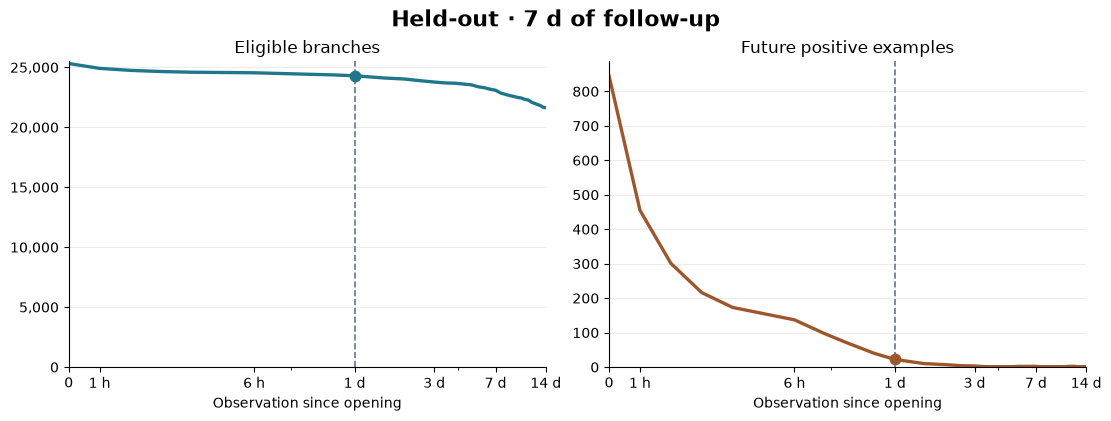

In [9]:
OBS_GRID = sorted(set(range(24, 337, 12)) | {0, 1, 2, 3, 4, 6, 9, 12, 18})


@lru_cache(maxsize=12)
def eligibility_curve(split, followup_hours):
    rows = []
    for hours in OBS_GRID:
        masks = window_masks(split, hours, followup_hours)
        rows.append((int(masks["eligible"].sum()), int(masks["future_delta"].sum())))
    return np.asarray(rows)


def duration(hours):
    days, remainder = divmod(hours, 24)
    return f"{days} d {remainder} h" if days and remainder else f"{days} d" if days else f"{remainder} h"


def plot_eligibility(split, observation_hours, followup_hours):
    curve = eligibility_curve(split, followup_hours)
    selected = window_masks(split, observation_hours, followup_hours)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")
    fig.suptitle(f"{SPLITS[split]} · {duration(followup_hours)} of follow-up",
                 fontsize=16, weight="bold")
    for col, (ax, title, mask, color) in enumerate(zip(
        axes, ("Eligible branches", "Future positive examples"),
        ("eligible", "future_delta"), ("#20768b", "#9d572d")
    )):
        ax.plot(OBS_GRID, curve[:, col], color=color, linewidth=2.4)
        ax.axvline(observation_hours, color="#657687", linestyle="--", linewidth=1.2)
        ax.scatter([observation_hours], [selected[mask].sum()], s=56, c=color, zorder=3)
        ax.set_xscale("symlog", linthresh=6)
        ax.set_xticks([0, 1, 6, 24, 72, 168, 336], ["0", "1 h", "6 h", "1 d", "3 d", "7 d", "14 d"])
        ax.set(xlim=(0, 336), ylim=(0, None), title=title, xlabel="Observation since opening")
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        ax.grid(axis="y", alpha=0.22)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    return fig


eligibility_fig = plot_eligibility("heldout", DEFAULT_OBSERVATION_HOURS, DEFAULT_FOLLOWUP_HOURS)
eligibility_fig.savefig(FIGURES / "eligibility_vs_observation.png", dpi=180, facecolor="white")
plt.show()

## Explore the two windows

Move the sliders independently to recompute eligibility, event counts, and the curve. The sliders use hours and display their duration in days and hours below. If the controls do not appear, install ipywidgets in the active notebook kernel and rerun this cell.

In [10]:
import ipywidgets as widgets


split_control = widgets.Dropdown(
    options=[(label, split) for split, label in SPLITS.items()], value="heldout", description="Split"
)
slider_style = {"description_width": "initial"}
observation = widgets.IntSlider(
    value=DEFAULT_OBSERVATION_HOURS, min=0, max=336, step=1,
    description="Observation (hours)", continuous_update=False, style=slider_style,
)
followup = widgets.IntSlider(
    value=DEFAULT_FOLLOWUP_HOURS, min=1, max=720, step=1,
    description="Follow-up (hours)", continuous_update=False, style=slider_style,
)
window_description = widgets.HTML()
metric_display = widgets.HTML()
curve_display = widgets.Image(format="png", layout=widgets.Layout(width="100%"))


def refresh(_change=None):
    split, hours, horizon = split_control.value, observation.value, followup.value
    data = window_metrics(split, hours, horizon)
    percent = data["Future delta prevalence"]
    observed_width = 100 * hours / (hours + horizon)
    window_description.value = (
        f"<b>Observe {duration(hours)} · predict over the next {duration(horizon)}</b>"
        "<div style='display:flex;height:8px;max-width:650px;margin:8px 0'>"
        f"<span style='width:{observed_width:.2f}%;background:#20768b'></span>"
        "<span style='flex:1;background:#9d572d'></span></div>"
        f"Branch opens → cutoff at {duration(hours)} → follow-up ends at {duration(hours + horizon)}."
    )
    table_rows = []
    for name, value in data.items():
        if name == "Future delta prevalence":
            value_text = f"{percent:.3%}" if np.isfinite(percent) else "—"
        else:
            value_text = f"{value:,}"
        table_rows.append(f"<tr><th scope='row'>{name}</th><td>{value_text}</td></tr>")
    metric_display.value = f"<table><tbody>{''.join(table_rows)}</tbody></table>"
    fig = plot_eligibility(split, hours, horizon)
    image = BytesIO()
    fig.savefig(image, format="png", dpi=130, facecolor="white")
    plt.close(fig)
    curve_display.value = image.getvalue()


for control in (split_control, observation, followup):
    control.observe(refresh, names="value")
refresh()
display(widgets.VBox([
    split_control, observation, followup, window_description, metric_display, curve_display,
]))